In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.simplefilter("ignore")

In [2]:
df = pd.read_csv('TravelInsurancePrediction.csv')

In [3]:
df.head()

,Unnamed: 0,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,0,31,Government Sector,Yes,400000,6,1,No,No,0
1,1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0


In [4]:
df.isna().sum()

Unnamed: 0             0
Age                    0
Employment Type        0
GraduateOrNot          0
AnnualIncome           0
FamilyMembers          0
ChronicDiseases        0
FrequentFlyer          0
EverTravelledAbroad    0
TravelInsurance        0
dtype: int64

In [5]:
# Dropping few columns from the dataset

df.drop(["Unnamed: 0", "GraduateOrNot"], axis=1, inplace=True)

df.head()

,Age,Employment Type,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,Government Sector,400000,6,1,No,No,0
1,31,Private Sector/Self Employed,1250000,7,0,No,No,0
2,34,Private Sector/Self Employed,500000,4,1,No,No,1
3,28,Private Sector/Self Employed,700000,3,1,No,No,0
4,28,Private Sector/Self Employed,700000,8,1,Yes,No,0


In [6]:
df.describe()

,Age,AnnualIncome,FamilyMembers,ChronicDiseases,TravelInsurance
count,1987.000000,1.987000e+03,1987.000000,1987.000000,1987.000000
mean,29.650226,9.327630e+05,4.752894,0.277806,0.357323
std,2.913308,3.768557e+05,1.609650,0.448030,0.479332
min,25.000000,3.000000e+05,2.000000,0.000000,0.000000
25%,28.000000,6.000000e+05,4.000000,0.000000,0.000000
50%,29.000000,9.000000e+05,5.000000,0.000000,0.000000
75%,32.000000,1.250000e+06,6.000000,1.000000,1.000000
max,35.000000,1.800000e+06,9.000000,1.000000,1.000000


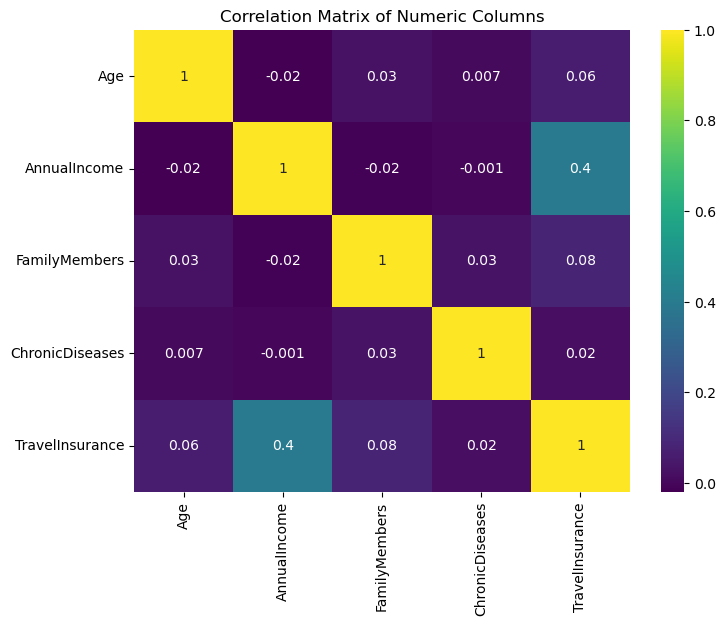

In [7]:
# Select only numeric columns for correlation
numeric_df = df.select_dtypes(include='number')

# Plot the correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.1g', cmap='viridis', cbar=True)
plt.title("Correlation Matrix of Numeric Columns")
plt.show()

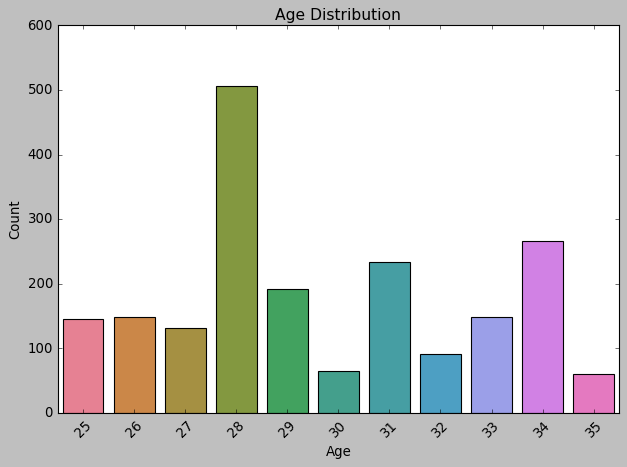

In [8]:
plt.style.use("classic")

# Generate a unique color for each age value
unique_ages = df["Age"].nunique()
palette = sns.color_palette("husl", unique_ages)  # Vibrant, distinct colors

# Create the plot
fig, ax = plt.subplots(figsize=(8, 6))
sns.countplot(x="Age", data=df, ax=ax, palette=palette, order=sorted(df["Age"].unique()))

# Beautify
ax.set_title("Age Distribution", fontsize=14)
ax.set_xlabel("Age", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

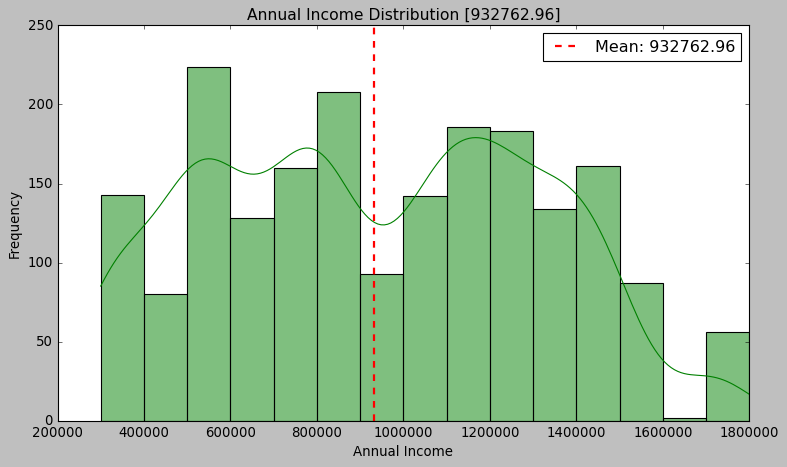

In [9]:
plt.style.use("classic")

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(df["AnnualIncome"], kde=True, color="green", ax=ax)

# Beautify
mean_income = df["AnnualIncome"].mean()
ax.axvline(mean_income, color='red', linestyle='--', linewidth=2, label=f"Mean: {mean_income:.2f}")
ax.set_title(f"Annual Income Distribution [{mean_income:.2f}]", fontsize=14)
ax.set_xlabel("Annual Income", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()

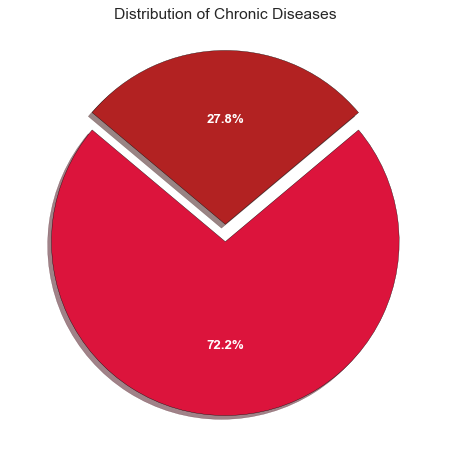

In [10]:
# Use a clean and professional style
plt.style.use("seaborn-v0_8")

# Get value counts
disease_counts = df["ChronicDiseases"].value_counts()
labels = ["Non-Chronic", "Chronic"]

# Create the plot
fig, ax = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax.pie(
    x=disease_counts,
    labels=labels,
    colors=["crimson", "firebrick"],
    shadow=True,
    explode=(0, 0.1),
    autopct="%1.1f%%",
    startangle=140,
    textprops=dict(color="white", fontsize=12),
)

# Beautify
ax.set_title("Distribution of Chronic Diseases", fontsize=14)
plt.setp(autotexts, weight="bold")
plt.tight_layout()
plt.show()

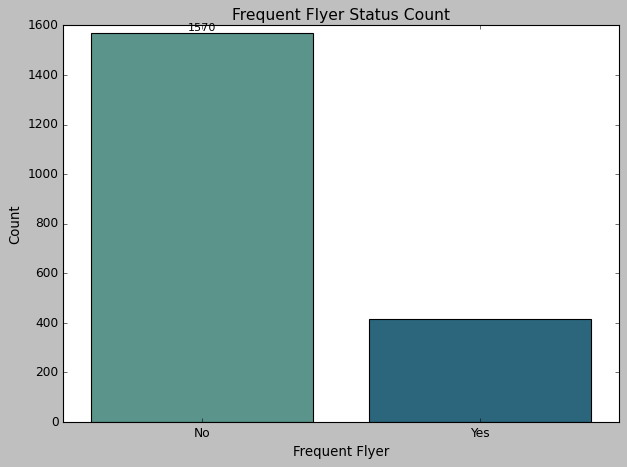

In [11]:
plt.style.use("classic")

# Create the plot
fig, ax = plt.subplots(figsize=(8, 6))
sns.countplot(x="FrequentFlyer", data=df, palette="crest", ax=ax)

# Beautify
ax.set_title("Frequent Flyer Status Count", fontsize=14)
ax.set_xlabel("Frequent Flyer", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
ax.bar_label(ax.containers[0], label_type="edge", fontsize=10)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()

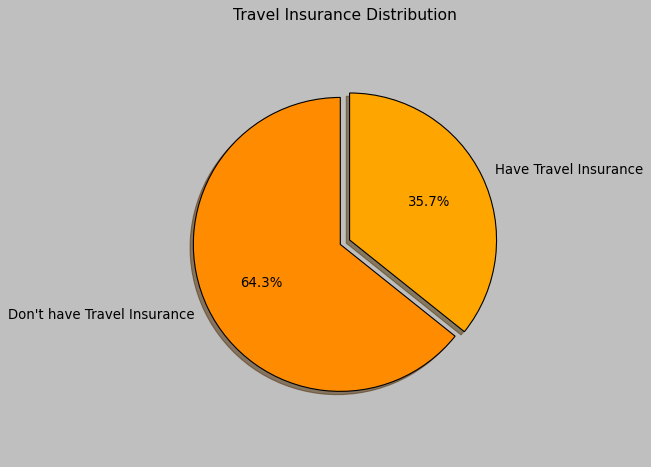

In [12]:
# Pie chart values and labels
values = df["TravelInsurance"].value_counts()
labels = ["Don't have Travel Insurance", "Have Travel Insurance"]

# Create pie chart
fig, ax = plt.subplots(figsize=(8, 6))
ax.pie(
    x=values,
    labels=labels,
    colors=["darkorange", "orange"],
    autopct="%1.1f%%",
    explode=(0, 0.07),
    shadow=True,
    startangle=90,
    wedgeprops={"edgecolor": "black"}
)

# Title and styling
ax.set_title("Travel Insurance Distribution", fontsize=14)
ax.axis("equal")

plt.tight_layout()
plt.show()

In [13]:
# Yes : 1, No : 0
df['FrequentFlyer'] = df['FrequentFlyer'].map({'Yes': 1, 'No': 0})

df['EverTravelledAbroad'] = df['EverTravelledAbroad'].map({'Yes': 1, 'No': 0})

# Government Sector : 1, Private Sector/Self Employed : 0
df["Employment Type"] = df["Employment Type"].map(
    {"Government Sector": 1, "Private Sector/Self Employed": 0}
)


In [14]:

# Having a look at the dataset after the numerical transformation
df.head()

,Age,Employment Type,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,1,400000,6,1,0,0,0
1,31,0,1250000,7,0,0,0,0
2,34,0,500000,4,1,0,0,1
3,28,0,700000,3,1,0,0,0
4,28,0,700000,8,1,1,0,0


In [15]:
# X data
X = df.drop("TravelInsurance", axis=1)



In [16]:
# Display first five rows of X
X.head()


,Age,Employment Type,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad
0,31,1,400000,6,1,0,0
1,31,0,1250000,7,0,0,0
2,34,0,500000,4,1,0,0
3,28,0,700000,3,1,0,0
4,28,0,700000,8,1,1,0


In [17]:
# y data
y = df["TravelInsurance"]

# Display first five values of y
y.head()

0    0
1    0
2    1
3    0
4    0
Name: TravelInsurance, dtype: int64

In [18]:
# Splitting the data into X train, X test and y train, y test

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



In [19]:
# Checking the length of training and testing data

len(X_train), len(X_test)




(1589, 398)

In [20]:
# Import Random Forest algorithm

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()




In [21]:
# Training the Random Forest model

rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [22]:
# Calculate the accuracy of Random Forest model

RandomForestClassifierScore = rf.score(X_test, y_test)

RandomForestClassifierScore


0.8115577889447236

In [23]:
# Display accuracy in percentage

print(
    "Accuracy obtained by RandomForestClassifier model:",
    RandomForestClassifierScore * 100
)

Accuracy obtained by RandomForestClassifier model: 81.15577889447236


In [24]:
# Import GridSearchCV
from sklearn.model_selection import GridSearchCV

# Define hyperparameter values
param_grid = {
    'bootstrap': [True],
    'max_depth': [80, 90, 100, 110, 120],
    'max_features': [2, 3],
    'min_samples_leaf': [3, 4, 5],
    'min_samples_split': [8, 10, 12],
    'criterion': ['gini', 'entropy'],
    'n_estimators': [100, 200, 300, 1000]
}

# Create GridSearchCV
grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=3,
    n_jobs=-1,
    verbose=2
)

In [ ]:
grid_search_rf.fit(X_train, y_train)

Fitting 3 folds for each of 720 candidates, totalling 2160 fits


In [ ]:
grid_search_rf.best_params_

In [ ]:
grid_search_rf.best_score_

In [ ]:
print('Improvement in Random Forest Classifier after GridSearchCV: {:.2f}%'.format(100 * (grid_search_rf.best_score_ - RandomForestClassifierScore) / RandomForestClassifierScore))

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, grid_search_rf_predict))